In [1]:
#Unpickling the data
import pickle

with open(r"C:\Users\anjal\Desktop\AI_ML\face_detection\data\images.p","rb") as f:#rb - read in binary
  images = pickle.load(f)#unzip kar rahe
with open(r"C:\Users\anjal\Desktop\AI_ML\face_detection\data\labels.p","rb") as f:
  labels = pickle.load(f)

In [2]:
print(images.shape)
print(labels.shape)

(371, 100, 100)
(371,)


In [3]:
set(labels)

{'Anjali', 'Sai', 'Subhasri', 'sanchita'}

In [4]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

labels = le.fit_transform(labels)

In [5]:
set(labels)

{0, 1, 2, 3}

In [6]:
le.inverse_transform([0,1,2,3])

array(['Anjali', 'Sai', 'Subhasri', 'sanchita'], dtype='<U8')

In [7]:
p = len(set(labels))
print("Total number of Persons : ",p)

Total number of Persons :  4


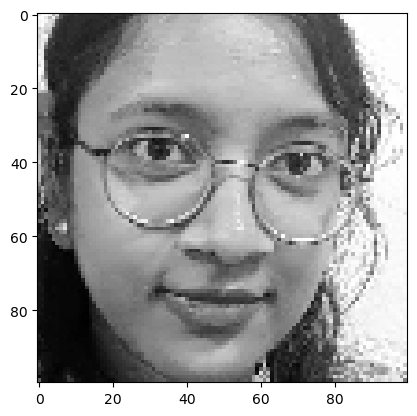

In [8]:
import matplotlib.pyplot as plt
plt.imshow(images[10],cmap='gray')
plt.show()

In [9]:
import cv2

In [10]:
def preprocessing(img):
  img = cv2.equalizeHist(img)#increases the contrast of image
  img = img.reshape(100,100,1)#reshape
  img = img/255#standardize
  return img

In [11]:
import numpy as np

In [12]:
images = np.array(list(map(preprocessing,images))) #map applies a function on a sequence and it returns the location so u need to unpack
print("Shape of Input : ",images.shape)

Shape of Input :  (371, 100, 100, 1)


In [13]:
from keras.utils import to_categorical
labels = to_categorical(labels)

In [14]:
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam

from keras.layers import Conv2D, MaxPooling2D, Flatten

In [15]:
#Model Training
def Lenet_Model():
  model = Sequential()
  #Convolutional and ReLU Layer
  model.add(Conv2D(30,(5,5),input_shape=(100,100,1),activation='relu'))
  #MaxPooling Layer
  model.add(MaxPooling2D(pool_size=(2,2)))

  #Convolutional and ReLU Layer
  model.add(Conv2D(15,(3,3),activation='relu'))
  #MaxPooling Layer
  model.add(MaxPooling2D(pool_size=(2,2)))

  #Flatten Layer/Input Layer
  model.add(Flatten())

  #Hidden Layers
  model.add(Dense(50,activation='relu'))

  #Output Layer
  model.add(Dense(p,activation='softmax'))
  model.compile(Adam(learning_rate=0.01),loss='categorical_crossentropy',metrics=['accuracy'])
  return model

In [16]:
model = Lenet_Model()
model.summary()

C:\Users\anjal\anaconda\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 96, 96, 30)          │             780 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 48, 48, 30)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 46, 46, 15)          │           4,065 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 23, 23, 15)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 7935)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 50)                  │         396,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             204 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 401,849 (1.53 MB)

 Trainable params: 401,849 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
h = model.fit(images,labels,validation_split=0.1,epochs=10)

Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 0.3604 - loss: 3.5610 - val_accuracy: 0.9211 - val_loss: 1.3262
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.7327 - loss: 0.8229 - val_accuracy: 0.9211 - val_loss: 0.2351
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.9489 - loss: 0.1932 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9850 - loss: 0.0496 - val_accuracy: 1.0000 - val_loss: 0.0090
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.9940 - loss: 0.0165 - val_accuracy: 1.0000 - val_loss: 0.0024
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 1.6028e-05
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.9970 - loss: 0.0080 - val_accuracy: 1.0000 - val_loss: 4.6103e-04
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.9760 - loss: 0.0725 - val_accuracy: 0

In [18]:
model.save('final_model.h5') #h5 is the file extension of keras model